In [1]:
import iris
import iris.plot as iplt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from matplotlib.colors import ListedColormap, BoundaryNorm
import statsmodels.formula.api as smf
import xarray as xr

### Get 5km hydraulic conductivity data

In [2]:
hc_5km = iris.load(f"../../Data/SoilStaticVariables/Mean_HydraulicConductivity_GB_5km.nc")[0]
lu_5km = iris.load(f"../../Data/SoilStaticVariables/Mean_EffectiveDepth_GB_5km.nc")[0]
fumax_5km = iris.load(f"../../Data/SoilStaticVariables/Mean_FUmax_GB_5km.nc")[0]

In [4]:
# Define class boundaries
q1 = 0.1
q2 = 0.15 
q3 = 0.3
q4 = 0.6
q5 = 0.9
q6 = 2
q7 = 3

# Define your quantile breakpoints as a list (add/remove as many as you like)
quantiles = [0.1, 0.3, 0.6, 0.9, 1, 2, 3]  
q0 = 0  # lower bound, adjust if needed

### Check plotting with boundaries

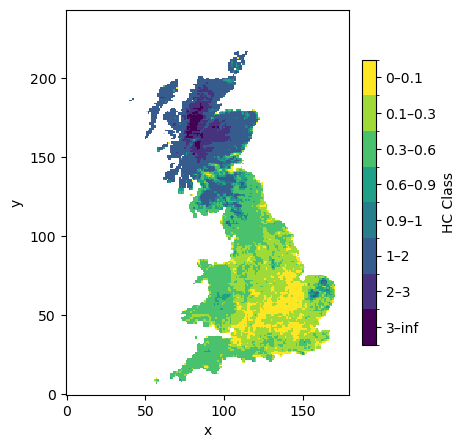

In [14]:
n_classes = len(quantiles) + 1

# Auto-generate labels from bin edges (reversed to match flipped class order)
edges = [q0] + quantiles + [np.inf]
class_labels = [f"{edges[i]}–{edges[i+1]}" for i in range(len(edges)-1)][::-1]

# Auto-generate colors from a colormap, sampled evenly across n_classes
base_cmap = plt.get_cmap('viridis')  # swap for 'RdYlBu_r', 'plasma', etc. as preferred
colors = [base_cmap(i) for i in np.linspace(0, 1, n_classes)]

# Get data
hk_vals = hc_5km['aggregated_mean']
if np.ma.is_masked(hk_vals):
    hk_vals = hk_vals.filled(np.nan)

# Convert data to classes (flip the order), bins built from the quantiles list
bins = [q0] + quantiles
classified = (n_classes + 1) - np.digitize(hk_vals, bins=bins)
classified = classified.astype(float)
classified[np.isnan(hk_vals)] = np.nan

# Assign back to cube
hc_5km["classified"] = (("y", "x"), classified)

fig, ax = plt.subplots(figsize=(4, 5))
cmap = ListedColormap(colors)
bounds = np.arange(0.5, n_classes + 1.5, 1)
norm = BoundaryNorm(bounds, cmap.N)
mesh = hc_5km["classified"].plot(ax=ax,cmap=cmap,norm=norm,add_colorbar=False)
ticks = np.arange(1, n_classes + 1)
cbar = fig.colorbar(mesh,ax=ax,orientation="vertical",fraction=0.046,pad=0.04,ticks=ticks)
cbar.ax.set_yticklabels(class_labels)
cbar.set_label("HC Class")
plt.show()